## HRV Cleaning
This notebook will exist to take the QC-dataframes from the other notebooks and use that to clean/flag our HRV data. We will assign timestamps of data into one of 3 categories:
- Acceptable -> We are confident this HRV data is accurate.
- Shaky -> We should look at this a little closer.
- Unacceptable -> We are confident this HRV data is altered by other artifacts.

### Files Used
- `processed-data\2.1_G1_movement_mask.csv` -> movement-burst mask, from `analysis\001_movement-artifacts.ipynb`
- `processed-data\2.1_G1_respiratory_mask.csv` -> respiration-context mask, from `analysis\002_respiratory-data.ipynb`
- `processed-data\2.1_G1_ppg_peak_mask.csv` -> PPG peak quality mask (10 s windows), from `analysis\004_ppg-peak-detection.ipynb`
- `processed-data\2.1_G1_ppg_beats.csv` -> beats derived from PPG Green, from `analysis\004_ppg-peak-detection.ipynb`. HRV is calculated from these intervals (`PPI`), not the device's `BI`.
- `data-files\2.1_G1_biometrics.csv` -> Contains phase markers

Notes on the PPG channels, the peak detection and the quality-check thresholds are in `analysis\004_ppg-peak-detection.ipynb`. Each mask's rules are summarised in `docs/Cleaning-Rules-v0.md`.

### How The Masks Are Combined
Each beat gets one value from each mask, and these decide its category:

| Mask | Unacceptable if | Shaky if |
|---|---|---|
| Movement (`001`) | `keep` is False (inside a movement burst or its 5 s padding) | — |
| Respiration (`002`) | `resp_quality` is Unacceptable (RR outside 9–24) or there is no reading | `resp_quality` is Shaky (RR 9–12 or 21–24) |
| PPG peaks (`004`) | `ppg_quality` is Unacceptable (fails heart rate, gap, ratio or template check) | — |

- **Unacceptable** if *any* mask says Unacceptable. A single artifact is enough to make the interval untrustworthy.
- **Shaky** if no mask says Unacceptable but respiration is Shaky. This is the only mask with a Shaky level. The other two are pass/fail.
- **Acceptable** otherwise.

### Assumptions
1. **Each beat takes each mask's value at the beat's own timestamp.** A beat's timestamp is the end of its interval (`004`, Assumption 5), so the interval itself starts up to ~1 s earlier. This is enough here: the movement mask already pads bursts by 5 s, each respiratory reading covers 30 s, and a PPG window's checks include every interval that overlaps it. The match is nearest-timestamp for movement and respiration, as `docs/Cleaning-Rules-v0.md` says, and the containing window for the PPG mask.
2. **A beat with no mask row near it is Unacceptable for that mask.** If a beat falls outside a mask's recording, its quality can't be confirmed. Nearest-timestamp matches only count within `MOVEMENT_TOLERANCE_S` / `RESP_TOLERANCE_S`, which are a few times the masks' sample spacing (see "Checking Mask Coverage").
3. **HRV measures that use successive intervals need both intervals kept.** Measures like RMSSD use the difference between neighbouring intervals, so a difference is only valid where two neighbouring beats are both kept. `segment_id` numbers each unbroken run of kept beats so later analysis can stay inside a run.

### Important Data Processing Steps To Note
**1. Beats and phases are loaded.** *(Code: "Loading Beats & Phases" section.)*
- One row per beat from `2.1_G1_ppg_beats.csv`, using `LocalTimestamp` (the same clock as all three masks and the biometrics file). No beats are removed: every beat is kept in the output with its flags.
- Phases are attached the same way as in `001`, `002` and `004`: each beat takes the most recent biometrics `event_marker` at or before it.

**2. Each mask is attached to the beats.** *(Code: "Attaching The Masks" section.)*

**3. The categories are combined using the table above.** *(Code: "Combining Into One Category" section.)*

**4. Usable data is summarised by phase.** *(Code: "Usable Data By Phase" section.)*

**5. Output: one row per beat.** *(Code: "Cleaned HRV Output" section.)*
- Saved to `processed-data/2.1_G1_hrv_clean.csv`.

### Global Variables & Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data-files")
PROCESSED_DIR = Path("../processed-data")
BEATS_FILE = PROCESSED_DIR / "2.1_G1_ppg_beats.csv"
BIOMETRICS_FILE = DATA_DIR / "2.1_G1_biometrics.csv"
MOVEMENT_MASK_FILE = PROCESSED_DIR / "2.1_G1_movement_mask.csv"
RESP_MASK_FILE = PROCESSED_DIR / "2.1_G1_respiratory_mask.csv"
PPG_MASK_FILE = PROCESSED_DIR / "2.1_G1_ppg_peak_mask.csv"
OUTPUT_FILE = PROCESSED_DIR / "2.1_G1_hrv_clean.csv"

MOVEMENT_TOLERANCE_S = 0.1 # Movement mask rows are ~0.04 s apart
RESP_TOLERANCE_S = 0.5 # Respiratory mask rows are ~0.09 s apart, at most ~0.21 s

MASKS = ["movement", "resp", "ppg"]
QUALITY_ORDER = ["Acceptable", "Shaky", "Unacceptable"]
QUALITY_COLORS = {"Acceptable": "#0ca30c", "Shaky": "#fab219", "Unacceptable": "#d03b3b"}

### Loading Beats & Phases
The beats come from `004_ppg-peak-detection.ipynb`. `PPI` is the interval in ms ending at each beat.

In [2]:
beats = pd.read_csv(BEATS_FILE, usecols=["LocalTimestamp", "EmotiBitTimestamp", "PPI"])

phases = (
    pd.read_csv(BIOMETRICS_FILE, usecols=["timestamp_unix", "event_marker"])
    .dropna()
    .sort_values("timestamp_unix")
    .rename(columns={"event_marker": "phase", "timestamp_unix": "phase_start"})
)
beats = pd.merge_asof(beats, phases, left_on="LocalTimestamp", right_on="phase_start", direction="backward").drop(columns="phase_start")
beats["phase"] = beats["phase"].fillna("unlabeled")
beats["minutes"] = (beats["LocalTimestamp"] - beats["LocalTimestamp"].iloc[0]) / 60

print(f"Beats: {len(beats)}, covering {beats['minutes'].iloc[-1]:.2f} min, total of all intervals {beats['PPI'].sum() / 60000:.2f} min")
print(f"Unlabeled beats (before the first phase marker): {(beats['phase'] == 'unlabeled').sum()}")
beats.head()

Beats: 6332, covering 84.77 min, total of all intervals 84.80 min
Unlabeled beats (before the first phase marker): 5


,LocalTimestamp,EmotiBitTimestamp,PPI,phase,minutes
0,1.757035e+09,2101202.0,1480.0,unlabeled,0.000000
1,1.757035e+09,2101642.0,440.0,unlabeled,0.007333
2,1.757035e+09,2102412.0,770.0,unlabeled,0.020167
3,1.757035e+09,2103291.9,880.0,unlabeled,0.034833
4,1.757035e+09,2103931.9,640.0,unlabeled,0.045500


### Checking Mask Coverage
For Assumption 2, this checks that every mask is sorted, how far apart its rows are, and how many beats fall outside its time span.

In [3]:
movement = pd.read_csv(MOVEMENT_MASK_FILE)
resp = pd.read_csv(RESP_MASK_FILE)
ppg = pd.read_csv(PPG_MASK_FILE)

coverage = []
for name, times in [("movement", movement["LocalTimestamp"]), ("resp", resp["timestamp_unix"]), ("ppg", ppg["window_start"])]:
    end = ppg["window_end"].iloc[-1] if name == "ppg" else times.iloc[-1]
    coverage.append({
        "mask": name, "sorted": times.is_monotonic_increasing,
        "median_step_s": times.diff().median(), "max_step_s": times.diff().max(),
        "beats_before_start": (beats["LocalTimestamp"] < times.iloc[0]).sum(),
        "beats_after_end": (beats["LocalTimestamp"] > end).sum(),
    })
pd.DataFrame(coverage).round(3)

,mask,sorted,median_step_s,max_step_s,beats_before_start,beats_after_end
0,movement,True,0.04,0.047,0,0
1,resp,True,0.09,0.211,23,0
2,ppg,True,10.00,10.000,0,0


### Attaching The Masks
- **Movement**: nearest movement-mask row within `MOVEMENT_TOLERANCE_S`. `movement_ok` is that row's `keep`.
- **Respiration**: nearest respiratory-mask row within `RESP_TOLERANCE_S`. `resp_quality` is that row's quality, or `No reading` if there is no row within the tolerance.
- **PPG peaks**: the PPG mask window where `window_start <= LocalTimestamp < window_end` (the last window's end is included, so the final beat is matched).

Beats with no match get `movement_ok` = False, `resp_quality` = `No reading` or `ppg_quality` = `No reading` (Assumption 2). The printout counts them.

In [4]:
beats = pd.merge_asof(
    beats, movement[["LocalTimestamp", "keep"]].rename(columns={"keep": "movement_ok"}),
    on="LocalTimestamp", direction="nearest", tolerance=MOVEMENT_TOLERANCE_S,
)
beats = pd.merge_asof(
    beats, resp[["timestamp_unix", "RR", "resp_quality"]],
    left_on="LocalTimestamp", right_on="timestamp_unix", direction="nearest", tolerance=RESP_TOLERANCE_S,
).drop(columns="timestamp_unix")

window = np.searchsorted(ppg["window_start"], beats["LocalTimestamp"], side="right") - 1
in_window = (window >= 0) & (beats["LocalTimestamp"] <= ppg["window_end"].iloc[-1])
beats["ppg_window"] = np.where(in_window, window, -1)
beats["ppg_quality"] = np.where(in_window, ppg["ppg_quality"].to_numpy()[window.clip(0)], None)

unmatched = {"movement": beats["movement_ok"].isna().sum(), "resp": beats["resp_quality"].isna().sum(), "ppg": beats["ppg_quality"].isna().sum()}
print("Beats with no matching mask row:", unmatched)
beats["movement_ok"] = beats["movement_ok"].astype("boolean").fillna(False).astype(bool)
beats["resp_quality"] = beats["resp_quality"].fillna("No reading")
beats["ppg_quality"] = beats["ppg_quality"].fillna("No reading")

print("Beats with respiration = No reading (unmatched, or after the last RR reading in 002):")
print(beats.loc[beats["resp_quality"] == "No reading", ["minutes", "phase", "ppg_quality"]].round(3).to_string())

Beats with no matching mask row: {'movement': np.int64(0), 'resp': np.int64(23), 'ppg': np.int64(0)}
Beats with respiration = No reading (unmatched, or after the last RR reading in 002):
      minutes         phase   ppg_quality
0       0.000     unlabeled  Unacceptable
1       0.007     unlabeled  Unacceptable
2       0.020     unlabeled  Unacceptable
3       0.035     unlabeled  Unacceptable
4       0.045     unlabeled  Unacceptable
5       0.060       startup  Unacceptable
6       0.070       startup  Unacceptable
7       0.081       startup  Unacceptable
8       0.092       startup  Unacceptable
9       0.100       startup  Unacceptable
10      0.112       startup  Unacceptable
11      0.118       startup  Unacceptable
12      0.128       startup  Unacceptable
13      0.141       startup  Unacceptable
14      0.152       startup  Unacceptable
15      0.171       startup  Unacceptable
16      0.179       startup  Unacceptable
17      0.190       startup  Unacceptable
18      0.201  

### Combining Into One Category
Each mask is first turned into an Acceptable / Shaky / Unacceptable value, as in the table at the top. The beat then takes the worst of the three. The second table shows which masks are responsible for the Unacceptable beats, because one beat can fail several.

In [5]:
beats["movement_level"] = np.where(beats["movement_ok"], "Acceptable", "Unacceptable")
beats["resp_level"] = beats["resp_quality"].replace({"No reading": "Unacceptable"})
beats["ppg_level"] = beats["ppg_quality"].replace({"No reading": "Unacceptable"})

level_cols = [f"{m}_level" for m in MASKS]
rank = {q: i for i, q in enumerate(QUALITY_ORDER)}
beats["hrv_quality"] = pd.Categorical(
    beats[level_cols].apply(lambda r: QUALITY_ORDER[max(rank[q] for q in r)], axis=1), categories=QUALITY_ORDER
)
beats["keep"] = beats["hrv_quality"].isin(["Acceptable", "Shaky"])

summary = beats.groupby("hrv_quality", observed=False).agg(beats=("PPI", "size"), minutes=("PPI", lambda s: s.sum() / 60000))
summary["pct_beats"] = 100 * summary["beats"] / summary["beats"].sum()
summary["pct_time"] = 100 * summary["minutes"] / summary["minutes"].sum()
print(summary.round(1).to_string())
print()
print("Share of beats each mask marks Unacceptable on its own:",
      {m: round(100 * (beats[f"{m}_level"] == "Unacceptable").mean(), 1) for m in MASKS})

              beats  minutes  pct_beats  pct_time
hrv_quality                                      
Acceptable     3197     43.0       50.5      50.7
Shaky           953     13.0       15.1      15.3
Unacceptable   2182     28.9       34.5      34.0

Share of beats each mask marks Unacceptable on its own: {'movement': np.float64(1.9), 'resp': np.float64(26.4), 'ppg': np.float64(9.8)}


In [6]:
failing = beats[beats["hrv_quality"] == "Unacceptable"]
failing[level_cols].eq("Unacceptable").apply(
    lambda r: " + ".join(m for m, failed in zip(MASKS, r) if failed), axis=1
).value_counts().to_frame("unacceptable_beats")

,unacceptable_beats
resp,1488
ppg,465
resp + ppg,109
movement + resp + ppg,44
movement,40
movement + resp,31
movement + ppg,5


How much the PPG peak mask and the respiratory mask overlap. If they mostly failed the same beats, combining them would cost little extra data. If they fail different beats, each one removes its own share.

In [7]:
without_ppg = (beats["movement_level"] != "Unacceptable") & (beats["resp_level"] != "Unacceptable")
print(f"Kept if only the movement and respiratory masks were used: {100 * without_ppg.mean():.1f}% of beats, "
      f"{100 * beats.loc[without_ppg, 'PPI'].sum() / beats['PPI'].sum():.1f}% of interval time")
pd.crosstab(beats["ppg_level"].rename("PPG mask"), beats["resp_level"].rename("respiratory mask"), margins=True)

Kept if only the movement and respiratory masks were used: 72.9% of beats, 72.7% of interval time


respiratory mask,Acceptable,Shaky,Unacceptable,All
PPG mask,,,,
Acceptable,3219,971,1519,5709
Unacceptable,305,165,153,623
All,3524,1136,1672,6332


### Continuous Runs Of Kept Beats
By Assumption 3, `segment_id` numbers each unbroken run of kept beats (`-1` for dropped beats). The run length matters for later HRV analysis, because measures like RMSSD need consecutive kept beats.

In [8]:
new_run = beats["keep"] & ~beats["keep"].shift(fill_value=False)
beats["segment_id"] = np.where(beats["keep"], new_run.cumsum() - 1, -1)

segments = beats[beats["keep"]].groupby("segment_id").agg(
    beats=("PPI", "size"), seconds=("PPI", lambda s: s.sum() / 1000), phase=("phase", "first")
)
print(f"Kept runs: {len(segments)}")
print(segments["seconds"].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
print(f"Kept time in runs of at least 30 s: {100 * segments.loc[segments['seconds'] >= 30, 'seconds'].sum() / segments['seconds'].sum():.1f}%")

Kept runs: 58
count     58.0
mean      57.9
std       58.3
min        1.6
25%       10.1
50%       30.4
75%       87.4
90%      149.2
max      259.9
Kept time in runs of at least 30 s: 88.0%


### Quality Over Time
Top three rows: each mask's level per beat. Bottom row: the combined category. Each beat is drawn as a bar covering its interval (from the previous beat to this one), so any long interval shows up as a long bar. Vertical bands mark phases, and phases longer than 2 minutes are labeled.

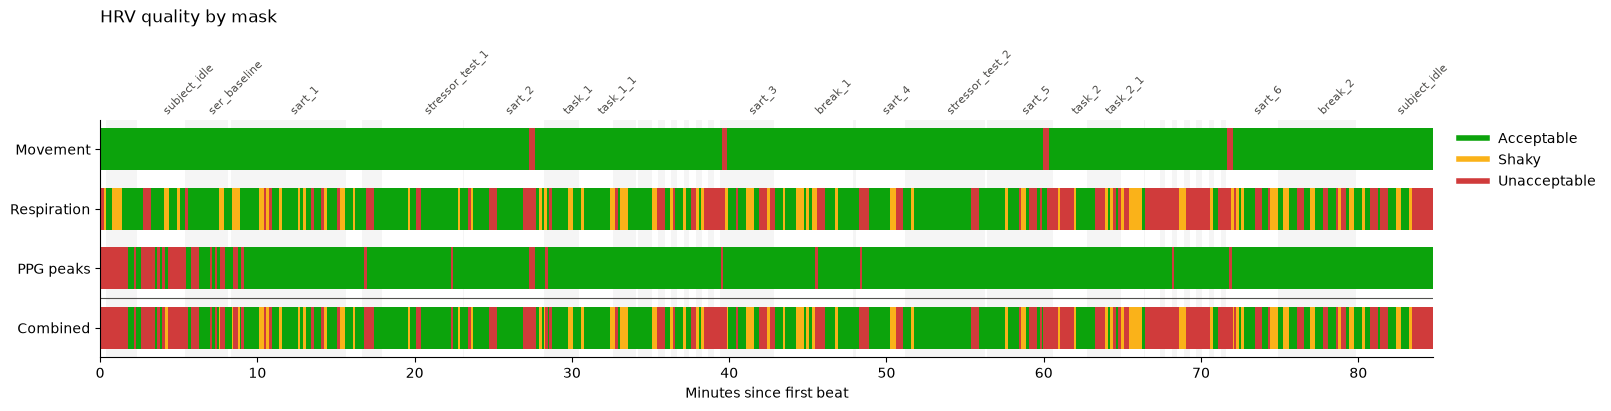

In [9]:
run_id = (beats["phase"] != beats["phase"].shift()).cumsum()
phase_segments = beats.groupby(run_id).agg(
    phase=("phase", "first"), start=("minutes", "first"), end=("minutes", "last")
).reset_index(drop=True)

rows = [("Movement", "movement_level"), ("Respiration", "resp_level"), ("PPG peaks", "ppg_level"), ("Combined", "hrv_quality")]
fig, ax = plt.subplots(figsize=(16, 4), constrained_layout=True)
for i, seg in phase_segments.iterrows():
    if i % 2 == 0:
        ax.axvspan(seg["start"], seg["end"], color="#000000", alpha=0.04, lw=0)
for y, (_, col) in enumerate(rows):
    for q in QUALITY_ORDER:
        pts = beats[beats[col].astype(str) == q]
        interval_min = pts["PPI"] / 60000
        ax.broken_barh(list(zip(pts["minutes"] - interval_min, interval_min)), (y - 0.35, 0.7), color=QUALITY_COLORS[q], lw=0)
ax.axhline(len(rows) - 1.5, color="#52514e", lw=0.8)

for _, seg in phase_segments.iterrows():
    if seg["end"] - seg["start"] >= 2:
        ax.text((seg["start"] + seg["end"]) / 2, 1.01, seg["phase"], transform=ax.get_xaxis_transform(),
                rotation=45, ha="left", va="bottom", fontsize=8, color="#52514e")

ax.set_yticks(range(len(rows)), [label for label, _ in rows])
ax.set_ylim(len(rows) - 0.5, -0.5)
ax.set_xlim(0, beats["minutes"].iloc[-1])
ax.set_xlabel("Minutes since first beat")
ax.set_title("HRV quality by mask", loc="left", pad=70)
handles = [plt.Line2D([], [], color=QUALITY_COLORS[q], lw=4) for q in QUALITY_ORDER]
ax.legend(handles, QUALITY_ORDER, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

### Usable Data By Phase
Share of each phase's interval time in each combined category, with the phase's total minutes in brackets. Time is the sum of the beat intervals, so a dropped long gap counts for its full length. `longest_run_s` is the longest continuous run of kept beats that starts in the phase.

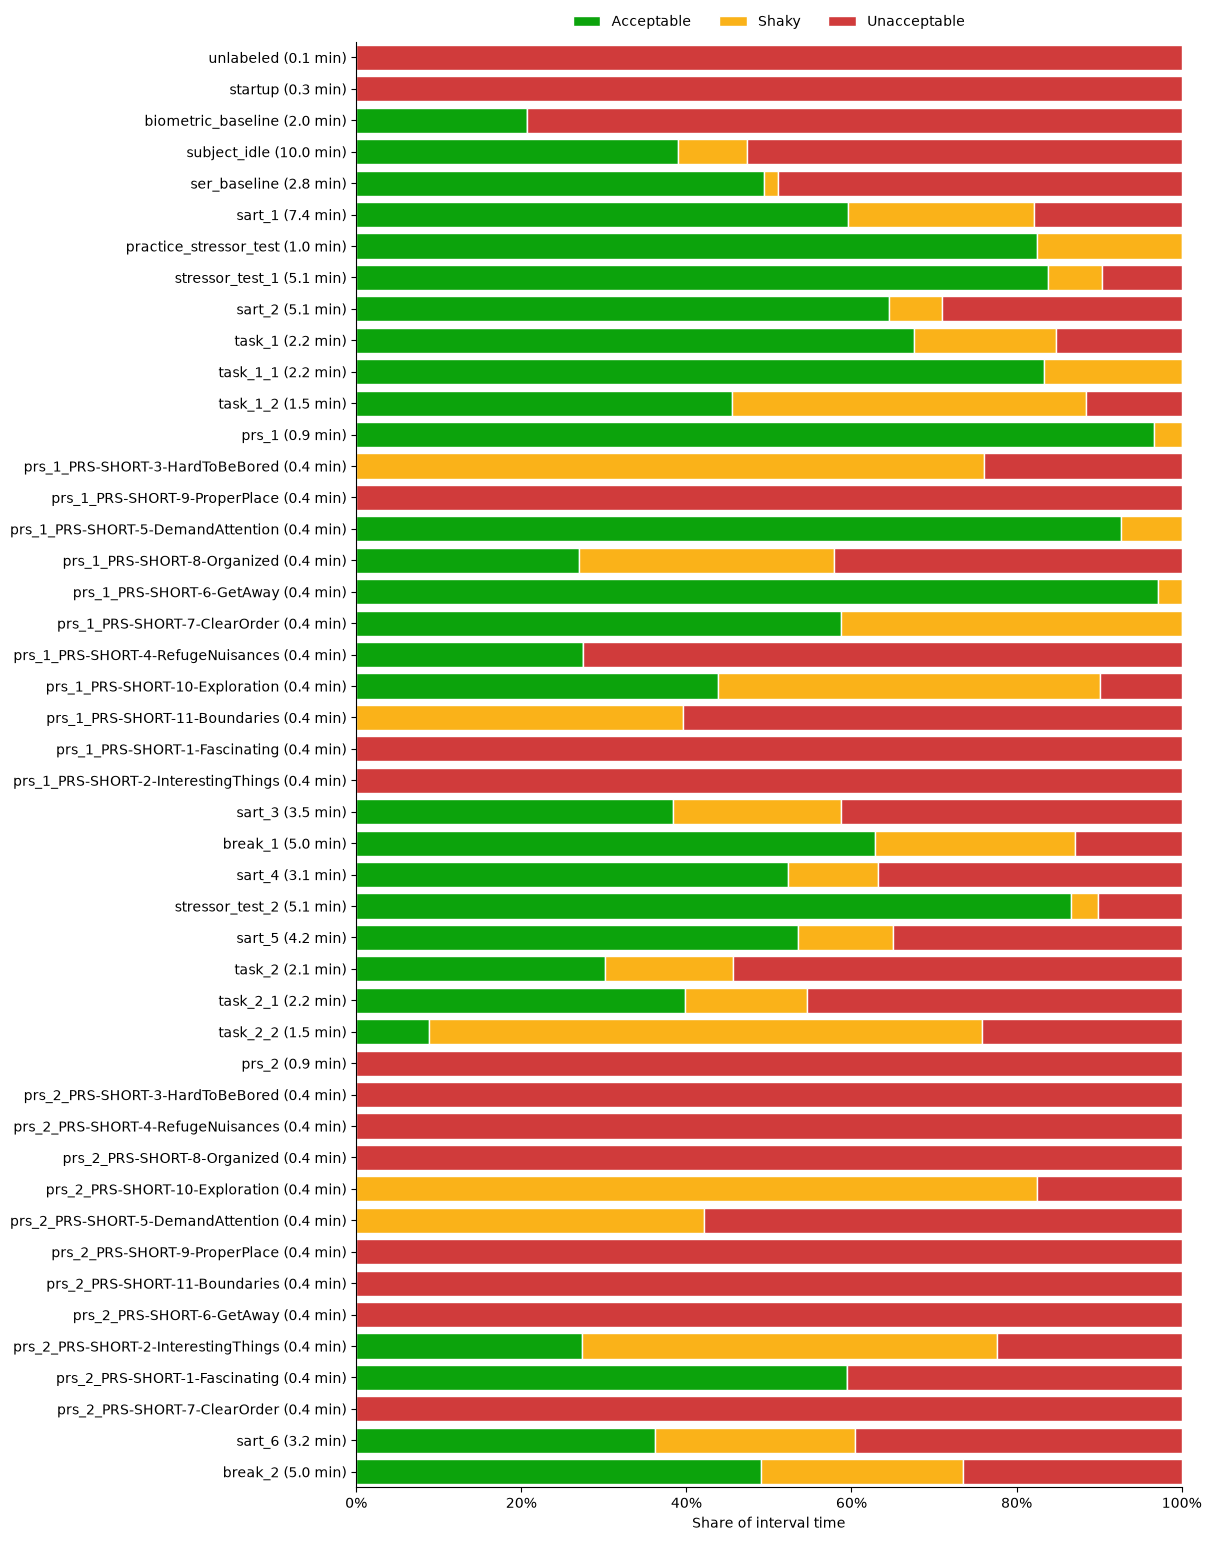

In [10]:
phase_order = list(dict.fromkeys(beats["phase"]))
time_by_phase = (beats.pivot_table(index="phase", columns="hrv_quality", values="PPI", aggfunc="sum", observed=False, fill_value=0)
                 .reindex(index=phase_order, columns=QUALITY_ORDER, fill_value=0) / 1000)
shares = time_by_phase.div(time_by_phase.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 0.3 * len(phase_order) + 1.5), constrained_layout=True)
left = np.zeros(len(shares))
for q in QUALITY_ORDER:
    ax.barh(range(len(shares)), shares[q], left=left, color=QUALITY_COLORS[q], label=q, edgecolor="white", linewidth=1, height=0.8)
    left += shares[q].to_numpy()
ax.set_yticks(range(len(shares)), [f"{p} ({m:.1f} min)" for p, m in zip(shares.index, time_by_phase.sum(axis=1) / 60)])
ax.set_ylim(len(shares) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Share of interval time")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [11]:
usable_by_phase = pd.DataFrame({
    "total_s": time_by_phase.sum(axis=1),
    "acceptable_s": time_by_phase["Acceptable"],
    "shaky_s": time_by_phase["Shaky"],
    "kept_pct": 100 * (time_by_phase["Acceptable"] + time_by_phase["Shaky"]) / time_by_phase.sum(axis=1),
    "longest_run_s": segments.groupby("phase")["seconds"].max().reindex(phase_order).fillna(0),
}).round(1)
usable_by_phase

,total_s,acceptable_s,shaky_s,kept_pct,longest_run_s
phase,,,,,
unlabeled,4.2,0.0,0.0,0.0,0.0
startup,19.1,0.0,0.0,0.0,0.0
biometric_baseline,120.3,24.8,0.0,20.6,20.3
subject_idle,597.4,232.8,49.8,47.3,160.4
ser_baseline,165.6,81.8,2.8,51.1,40.4
sart_1,441.7,263.4,99.5,82.2,150.6
practice_stressor_test,57.2,47.2,10.0,100.0,0.0
stressor_test_1,304.7,255.5,19.6,90.3,113.2
sart_2,305.5,197.0,19.6,70.9,100.3


The same summary with sub-phases grouped under their parent (for example `prs_1_PRS-SHORT-3-HardToBeBored` under `prs_1`, `task_1_1` under `task_1`). The PRS items and task sub-phases are too short to be read on their own.

In [12]:
parent_phase = beats["phase"].str.replace(r"^((?:prs|task)_\d)_.*$", r"\1", regex=True)
parent_order = list(dict.fromkeys(parent_phase))
time_by_parent = (beats.assign(parent=parent_phase)
                  .pivot_table(index="parent", columns="hrv_quality", values="PPI", aggfunc="sum", observed=False, fill_value=0)
                  .reindex(index=parent_order, columns=QUALITY_ORDER, fill_value=0) / 1000)
pd.DataFrame({
    "total_s": time_by_parent.sum(axis=1),
    "kept_s": time_by_parent["Acceptable"] + time_by_parent["Shaky"],
    "kept_pct": 100 * (time_by_parent["Acceptable"] + time_by_parent["Shaky"]) / time_by_parent.sum(axis=1),
    "acceptable_s": time_by_parent["Acceptable"],
}).round(1)

,total_s,kept_s,kept_pct,acceptable_s
parent,,,,
unlabeled,4.2,0.0,0.0,0.0
startup,19.1,0.0,0.0,0.0
biometric_baseline,120.3,24.8,20.6,24.8
subject_idle,597.4,282.7,47.3,232.8
ser_baseline,165.6,84.6,51.1,81.8
sart_1,441.7,362.9,82.2,263.4
practice_stressor_test,57.2,57.2,100.0,47.2
stressor_test_1,304.7,275.1,90.3,255.5
sart_2,305.5,216.6,70.9,197.0


### Observations
Each observation names the section whose output supports it.
- **All three masks line up with the beats** *(Checking Mask Coverage, Attaching The Masks)*: the movement and PPG masks cover every beat. The respiratory recording starts after the first 23 beats, and the last 3 beats come after the final RR reading. These 26 beats are respiration `No reading` and are Unacceptable (Assumption 2). The first 23 also fail the PPG mask, while the last 3 pass it, so this rule only decides the outcome for those 3.
- **65.5% of beats are kept, covering 55.9 minutes (66.0%) of the 84.8 minutes of intervals** *(Combining Into One Category)*: 3197 beats are Acceptable (43.0 min) and 953 are Shaky (13.0 min). 2182 beats (28.9 min) are Unacceptable.
- **The respiratory mask now removes the most data** *(Combining Into One Category)*: on its own it marks 26.4% of beats Unacceptable, compared with 9.8% for the PPG mask and 1.9% for movement. It is involved in 1672 of the 2182 Unacceptable beats, and 1488 of those fail *only* this mask. Using only the movement and respiratory masks would keep 72.9% of beats, so adding the PPG mask costs 7.4 percentage points.
- **The respiratory and PPG masks fail mostly different beats** *(Combining Into One Category, overlap table)*: of the 5709 beats that pass the PPG mask, 1519 (26.6%) are then removed by respiration. Respiration fails at about the same rate among beats failing the PPG mask (153 of 623, 24.6%), so the two masks pick up different problems.
- **Movement adds little** *(Combining Into One Category)*: only 40 beats fail movement alone. The other 80 movement-failed beats also fail another mask.
- **Most kept time is in usable lengths** *(Continuous Runs Of Kept Beats)*: the 4150 kept beats form 58 unbroken runs. The median run is 30.4 s, the 90th percentile is 149.2 s, and the longest is 259.9 s (starting in `sart_4`). 88.0% of kept time is in runs of at least 30 s.
- **The two baselines have some data, but not much** *(Usable Data By Phase)*: `biometric_baseline` keeps 24.8 s (20.6%, longest run 20.3 s) and `ser_baseline` keeps 84.6 s (51.1%, longest run 40.4 s). `unlabeled` and `startup` keep none.
- **`prs_2` is the only other phase that's nearly empty** *(Usable Data By Phase)*: it keeps 60.5 s (19.5%) when grouped under its parent. `004` shows 96.8% of its PPG windows pass, so respiration is the cause, as `002` also found for this block.
- **The best-covered phases span the session** *(Usable Data By Phase)*: `task_1` keeps 91.3% (323.1 s), `stressor_test_1` 90.3% (275.1 s), `stressor_test_2` 89.9% (273.8 s), `break_1` 87.1% (260.9 s) and `sart_1` 82.2% (362.9 s).

### Conclusions
- **The cleaned output is `2.1_G1_hrv_clean.csv`: every beat, with its flags, an overall category and a run number.** *Reasoning:* nothing is deleted, so later analysis can use `keep`, use only `Acceptable`, or apply a different rule, and can always see which mask dropped a beat. This fits the task's goal of documenting what is usable, questionable and missing rather than throwing data away.
- **Respiration, not beat detection, is now the main limit on usable HRV.** *Reasoning:* the respiratory mask removes 26.4% of beats, and is the only failing mask for 1488 of them. The PPG mask removes 9.8%, and movement 1.9%. With beats derived from PPG Green, the beat-quality problem that used to dominate has mostly gone (`004`).
- **Baseline comparisons are now possible in principle, but `ser_baseline` is the only realistic reference, and only if a minimum-duration rule allows it.** *Reasoning:* `ser_baseline` has 84.6 s kept, with a longest run of 40.4 s. `biometric_baseline` has only 24.8 s, because PPG quality is low in the first ~10 minutes (`004`), so it shouldn't be relied on without a source saying that's enough. `break_1` remains an alternative reference, with 260.9 s kept.
- **HRV measures should be calculated within runs, not across them.** *Reasoning:* the kept data is broken into 58 runs (Assumption 3). Differences between intervals on either side of a dropped stretch don't represent consecutive heartbeats, so they would distort RMSSD-type measures.
- **`keep` means the data passed the cleaning rules. It doesn't mean RMSSD is accurate.** *Reasoning:* `004` shows RMSSD from green and infrared disagrees even in windows that pass (correlation 0.20), and Source 1 found RMSSD insufficient against ECG in windows passing the same checks. Heart rate from these beats is much better supported than RMSSD.
- **Deciding which phases are "usable" needs a minimum-duration rule, which hasn't been chosen.** *Reasoning:* the per-phase table gives kept seconds and the longest run, but how many seconds of clean data an HRV measure needs depends on the measure and should come from a source, as the other thresholds do.


### Cleaned HRV Output
One row per beat. Every beat is kept in the file with its flags, so later analysis can choose to use only `keep`, only `Acceptable`, or a different rule.

Columns: `LocalTimestamp` (same clock as `timestamp_unix` in the biometrics file), `EmotiBitTimestamp`, `PPI` (ms, derived from PPG Green in `004`), `phase`, `movement_ok`, `RR`, `resp_quality`, `ppg_quality`, `hrv_quality`, `keep`, `segment_id`.

In [13]:
hrv_clean = beats[["LocalTimestamp", "EmotiBitTimestamp", "PPI", "phase", "movement_ok", "RR", "resp_quality",
                   "ppg_quality", "hrv_quality", "keep", "segment_id"]]
print(f"Kept: {hrv_clean['keep'].sum()} of {len(hrv_clean)} beats ({100 * hrv_clean['keep'].mean():.1f}%)")

OUTPUT_FILE.parent.mkdir(exist_ok=True)
hrv_clean.to_csv(OUTPUT_FILE, index=False)
hrv_clean.head()

Kept: 4150 of 6332 beats (65.5%)


,LocalTimestamp,EmotiBitTimestamp,PPI,phase,movement_ok,RR,resp_quality,ppg_quality,hrv_quality,keep,segment_id
0,1.757035e+09,2101202.0,1480.0,unlabeled,True,NaN,No reading,Unacceptable,Unacceptable,False,-1
1,1.757035e+09,2101642.0,440.0,unlabeled,True,NaN,No reading,Unacceptable,Unacceptable,False,-1
2,1.757035e+09,2102412.0,770.0,unlabeled,True,NaN,No reading,Unacceptable,Unacceptable,False,-1
3,1.757035e+09,2103291.9,880.0,unlabeled,True,NaN,No reading,Unacceptable,Unacceptable,False,-1
4,1.757035e+09,2103931.9,640.0,unlabeled,True,NaN,No reading,Unacceptable,Unacceptable,False,-1
